# Preprocessing · Clean, split and transform
Run after `01_eda.ipynb`. This notebook implements all cleaning and preprocessing. No model selection uses calibration or test rows.

## 1. Schema and explicit configuration

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "Datasets").is_dir() else Path.cwd().parent
if not (ROOT / "Datasets").is_dir():
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
DATA = ROOT / "Datasets"
WORK = DATA / "_working"  # Local intermediate files; ignored by Git.
FIGURES = ROOT / "figures"
WORK.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
CSV = WORK / "Combined_dataset.csv"
import joblib
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = [
    "Ammonia",
    "BOD",
    "Dissolved oxygen",
    "Orthophosphate",
    "pH",
    "Temperature",
    "Nitrogen",
    "Nitrate",
]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    Missing/nonfinite values produce NaN rather than silently passing a test.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result

def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for unit/measurement review, not converted.
    Every input gets a fixed missing/invalid flag, even if train has no missingness.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)

CONFIG = {'seed': 42, 'train_end': '2018-12-31', 'validation_end': '2019-12-31', 'calibration_end': '2020-12-31', 'max_train_rows': 300000, 'max_tuning_rows': 50000, 'threads': 4, 'xgb_estimators': 1000, 'xgb_depths': [4, 6], 'mlp_widths': [[64, 32], [128, 64]], 'mlp_epochs': 60, 'mlp_patience': 10, 'batch_size': 2048, 'alpha': 0.1, 'explanation_rows': 2000}
CONFIG["data"] = str(CSV)

## 2. Cleaning and chronological partitions
Remove exact duplicates before splitting. Do not impute targets, dates or missing site identifiers. Keep original source-row IDs for traceability.

| Partition | Dates | Purpose |
|---|---|---|
| Training | Through 2018 | Fit preprocessing and model parameters |
| Validation | 2019 | Early stopping, model and blend selection |
| Calibration | 2020 | Held-out residual interval radius |
| Test | 2021–2023 | Final comparison after selection |

Use seed 42 to sample 300,000 historical training rows and 50,000 validation tuning rows. Evaluate on all 202,886 test rows. Site identifiers are metadata, not predictors. Historical sites can recur, so this is not an unseen-site evaluation.

In [2]:
def read_dataset(path):
    df = pd.read_csv(path)
    required = set(META + FEATURES + [TARGET, "CCME_WQI"])
    if required - set(df.columns):
        raise ValueError(f"Dataset lacks columns: {sorted(required - set(df.columns))}")
    return df

def prepare(frame):
    """Keep source row IDs for traceability; never impute a target or a date."""
    df = frame.copy()
    df.insert(0, "source_row", np.arange(len(df)))
    duplicates = df.drop(columns="source_row").duplicated()
    date = pd.to_datetime(df.Date, format="%d-%m-%Y", errors="coerce")
    y = pd.to_numeric(df[TARGET], errors="coerce")
    invalid = date.isna() | ~y.between(0, 100) | df.Country.isna() | df.Area.isna()
    counts = {
        "exact_duplicates_removed": int(duplicates.sum()),
        "invalid_metadata_or_target": int(invalid.sum()),
    }
    df = df.loc[~duplicates & ~invalid].copy()
    df["parsed_date"] = date.loc[df.index]
    df[TARGET] = y.loc[df.index]
    return df, counts

def temporal_split(df, config):
    bounds = [pd.Timestamp(config[k]) for k in ["train_end", "validation_end", "calibration_end"]]
    if not bounds[0] < bounds[1] < bounds[2]:
        raise ValueError("Split boundaries must increase strictly")
    date = df.parsed_date
    masks = [
        date <= bounds[0],
        (date > bounds[0]) & (date <= bounds[1]),
        (date > bounds[1]) & (date <= bounds[2]),
        date > bounds[2],
    ]
    splits = dict(
        zip(["train", "validation", "calibration", "test"], [df.loc[mask].copy() for mask in masks])
    )
    if any(part.empty for part in splits.values()):
        raise ValueError("Every chronological partition must contain observations")
    return splits

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

def split_summary(part):
    return {
        "rows": len(part),
        "start": str(part.parsed_date.min().date()),
        "end": str(part.parsed_date.max().date()),
        "countries": part.Country.value_counts().to_dict(),
        "sites": int(part.groupby(["Country", "Area"]).ngroups),
        "mean_target": float(part[TARGET].mean()),
    }

## 3. Fit transforms on training only
The eight measurements become 16 inputs after adding fixed missing/invalid flags. Median imputation uses only the training sample. XGBoost uses unscaled inputs. Ridge and the MLP additionally use `asinh` followed by standard scaling: `asinh` reduces concentration skew and supports legitimate subzero temperatures.

The file in `Datasets/_working/` is a disposable local cache connecting notebook stages. It is excluded from Git; running these cells recreates it.

In [3]:
print("Reading and auditing the complete combined dataset...", flush=True)
raw = read_dataset(CONFIG["data"])
audit = json.loads((WORK / "data_audit.json").read_text())
clean, removed = prepare(raw)
audit.update(removed)
splits = temporal_split(clean, CONFIG)
manifest = {key: split_summary(part) for key, part in splits.items()}
train = sample(splits["train"], CONFIG["max_train_rows"], CONFIG["seed"])
tuning = sample(splits["validation"], CONFIG["max_tuning_rows"], CONFIG["seed"])
manifest["training_rows_used"] = len(train)
manifest["tuning_rows_used"] = len(tuning)
train_sites = pd.MultiIndex.from_frame(splits["train"][["Country", "Area"]])
test_sites = pd.MultiIndex.from_frame(splits["test"][["Country", "Area"]])
manifest["test_rows_at_sites_seen_before_2019"] = float(test_sites.isin(train_sites).mean())
x = quality_features(train)
y = train[TARGET].to_numpy()
xv, yv = quality_features(tuning), tuning[TARGET].to_numpy()
# All transforms learn exclusively from the shared training sample.
tree_pre = SimpleImputer(strategy="median", keep_empty_features=True)
xt, xvt = tree_pre.fit_transform(x), tree_pre.transform(xv)
# Concentrations span orders of magnitude. asinh is smooth and also handles
# legitimate subzero temperatures without a learned clipping threshold.
neural_pre = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    FunctionTransformer(np.arcsinh, validate=False),
    StandardScaler(),
)
xn, xvn = (
    neural_pre.fit_transform(x).astype("float32"),
    neural_pre.transform(xv).astype("float32"),
)

manifest["retained_rows"] = len(clean)
audit["retained_rows"] = len(clean)
# Keep only frames needed by the next notebook. The full historical partition
# is summarized in manifest; all models use the same 300,000 sampled rows.
bundle = {
    "train": train, "tuning": tuning,
    "splits": {name: splits[name] for name in ["validation", "calibration", "test"]},
    "manifest": manifest, "audit": audit, "config": CONFIG,
    "tree_pre": tree_pre, "neural_pre": neural_pre,
    "xt": xt, "xvt": xvt, "xn": xn, "xvn": xvn,
    "y": y, "yv": yv,
}
joblib.dump(bundle, WORK / "prepared.joblib", compress=3)
(WORK / "split_manifest.json").write_text(json.dumps(manifest, indent=2))
display(pd.DataFrame({k:v for k,v in manifest.items() if isinstance(v, dict)}).T)
print(f"Shared training sample: {len(train):,}; tuning sample: {len(tuning):,}")
print(f"Test rows at historical sites: {manifest['test_rows_at_sites_seen_before_2019']:.1%}")
print("Saved local preparation cache for the model notebook.")

Reading and auditing the complete combined dataset...
Shared training sample: 300,000; tuning sample: 50,000
Test rows at historical sites: 85.9%
Saved local preparation cache for the model notebook.


,rows,start,end,countries,sites,mean_target
train,2478761,1940-01-02,2018-12-28,"{'England': 1887124, 'USA': 371009, 'Ireland':...",55731,84.148022
validation,87177,2019-01-01,2019-12-31,"{'England': 64121, 'Ireland': 14404, 'USA': 82...",14705,90.376429
calibration,49182,2020-01-01,2020-12-31,"{'England': 29453, 'Ireland': 12846, 'USA': 65...",11484,91.920604
test,202886,2021-01-01,2023-12-17,"{'England': 147199, 'Ireland': 36230, 'USA': 1...",17462,91.410002


## 4. Inspect separation and fitted values

In [4]:
assert splits["validation"].parsed_date.min() > pd.Timestamp(CONFIG["train_end"])
assert splits["test"].parsed_date.min() > pd.Timestamp(CONFIG["calibration_end"])
assert xt.shape[1] == xn.shape[1] == 16
assert np.isfinite(xt).all() and np.isfinite(xn).all()
display(pd.DataFrame({"input": quality_features(train).columns, "training_median": tree_pre.statistics_}))

,input,training_median
0,Ammonia (mg/l),0.060
1,Biochemical Oxygen Demand (mg/l),2.600
2,Dissolved Oxygen (mg/l),10.200
3,Orthophosphate (mg/l),0.122
4,pH (ph units),7.780
5,Temperature (cel),11.460
6,Nitrogen (mg/l),4.140
7,Nitrate (mg/l),4.500
8,Ammonia (mg/l)__missing,0.000
9,Biochemical Oxygen Demand (mg/l)__missing,0.000


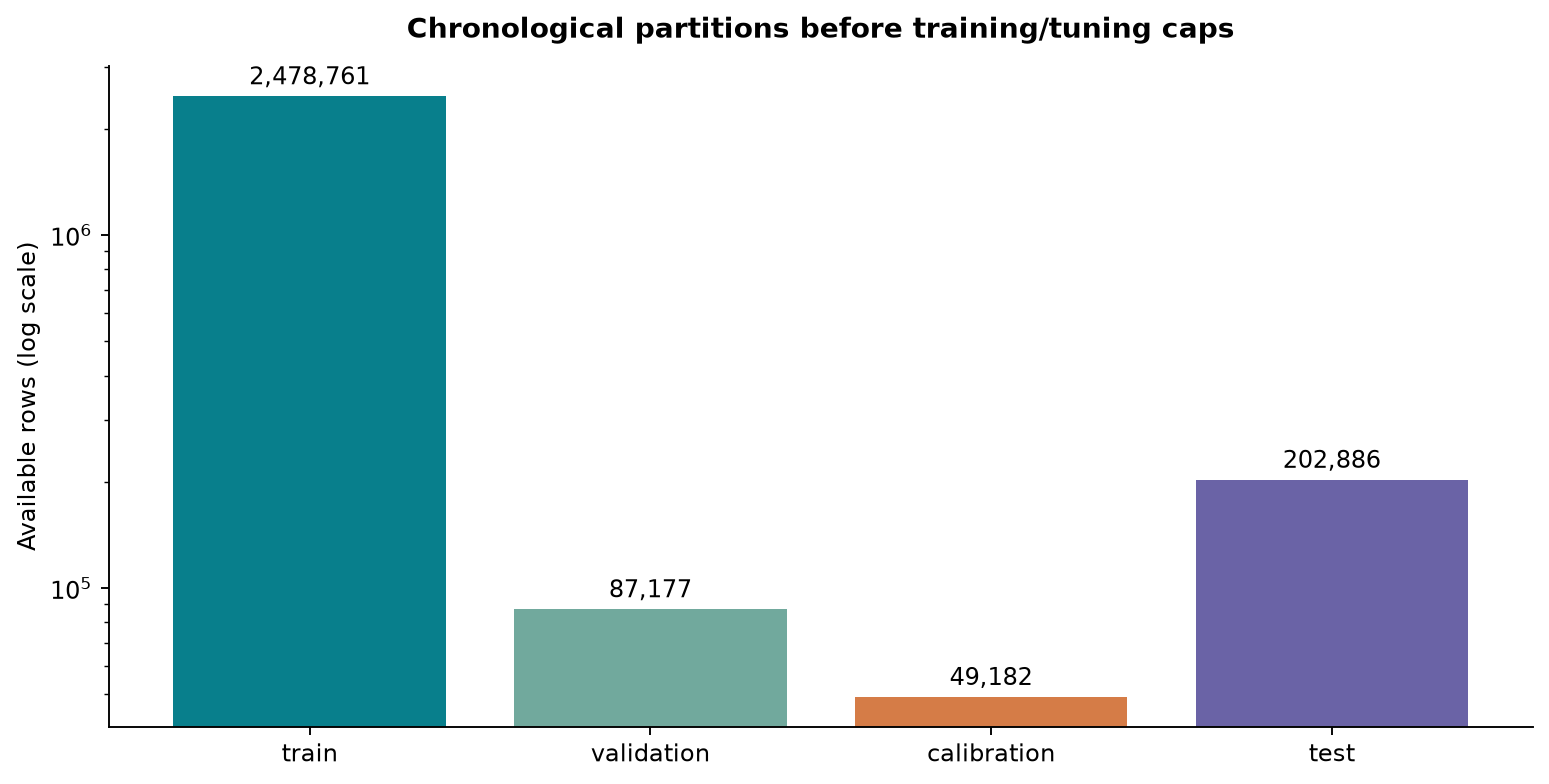

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
parts = ["train", "validation", "calibration", "test"]
counts = [manifest[k]["rows"] for k in parts]
ax.bar(parts, counts, color=["#087f8c", "#71a99d", "#d57c47", "#6a63a6"])
ax.set(yscale="log", ylabel="Available rows (log scale)", title="Chronological partitions before training/tuning caps")
for i, count in enumerate(counts): ax.text(i, count*1.08, f"{count:,}", ha="center")
show_figure(fig, "temporal_split.png")

## Next step
Run **02_Model_Application.ipynb**. It trains and compares the models, saves predictions and weights, explains feature reliance and demonstrates predictions from reloaded models. No supplementary scripts or source package are required.